# Phase I · 02 · How does the baseline CNN behave?

Here the trained baseline CNN is a **black box**: we change the input images and record only its output, P(FAKE). The weights and the 0.5 threshold stay fixed, and nothing inside the network is inspected; that is Phase II (`phase2/01_cnn_internals.ipynb`).

We apply JPEG compression, Gaussian blur, downsize-and-resize and Gaussian noise at four strengths each to the same **10,000 validation images** (5,000 REAL, 5,000 FAKE) and follow every image through all 17 conditions. Accuracy at each setting is only the starting point. The figures show *how* predictions move: which class loses detections, whether images move together, and which individual images flip.

| Phase I notebook | Question |
| --- | --- |
| `01_training_data_exploration.ipynb` | What differs between REAL and FAKE training images before any model sees them? |
| `02_cnn_behaviour.ipynb` | How do the baseline CNN's outputs move when we edit the images? |
| `03_resnet18_behaviour.ipynb` | The same edits for the fine-tuned ResNet18 |
| `04_what_fools_the_detectors.ipynb` | Which systematic patterns sit behind the errors of both models? |

The model, its saved predictions and 27 preview images are bundled inside this notebook, so it runs without the dataset and without training. The cells are Sections 9–11 of `baseline_training.ipynb`, moved here with new section numbers. Learning curves, the epoch report and the official test evaluation stay in `baseline_training.ipynb`: they describe performance, which is not what Phase I asks for.

## 1. Environment and notebook implementation

Use Python 3.12 and select that environment as the notebook kernel in VS Code or Jupyter. If dependencies are missing, set `INSTALL_DEPENDENCIES = True` in the next cell, run it once, restart the kernel if prompted, then set it back to `False`. This installs packages in the current kernel environment; the default Run All does not install or download anything.

The helper cells below contain the entire implementation. The collapsed **bundled baseline** cell carries the selected trained weights, numerical results, and static figures, so copying this `.ipynb` is enough to share the baseline. You can leave that cell collapsed.

In [1]:
INSTALL_DEPENDENCIES = False
PACKAGES = [
    "kagglehub==1.0.3",
    "torch==2.15.0",
    "numpy==2.5.4",
    "pillow==13.0.0",
    "scikit-learn==1.9.1",
    "matplotlib==3.11.2",
    "jupyterlab==4.6.5",
    "ipykernel==7.4.0",
    "nbformat==5.11.1",
    "nbclient==0.11.0",
    "plotly==7.1.0",
    "anywidget==0.11.0",
    "ipywidgets==8.1.9",
]

if INSTALL_DEPENDENCIES:
    get_ipython().run_line_magic("pip", "install " + " ".join(PACKAGES))
else:
    print("Using the current kernel environment; installation is disabled.")


Using the current kernel environment; installation is disabled.


In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from io import BytesIO, StringIO
from types import SimpleNamespace
import base64
import csv
import hashlib
import importlib.metadata
import json
import logging
import os
import platform
import random
import shutil
import sys
import tarfile
import tempfile
import time

NOTEBOOK_PATH = Path.cwd().resolve() / "02_cnn_behaviour.ipynb"
# Phase notebooks sit one folder below the repository root; data, runs and results stay at the root.
ROOT = next(
    (p for p in (NOTEBOOK_PATH.parent, *NOTEBOOK_PATH.parents) if (p / "team-info.json").exists()),
    NOTEBOOK_PATH.parent,
)
os.environ.setdefault(
    "MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "cifake-matplotlib")
)

import numpy as np
import torch
from torch import nn
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(4)


def read_json(path):
    return json.loads(Path(path).read_text())


def read_csv(path):
    with Path(path).open(newline="") as handle:
        return list(csv.DictReader(handle))


def show_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines += ["| " + " | ".join(str(value) for value in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def snapshot_notebook(source_dir):
    """Record the notebook and the code actually executed for a new training run."""
    if not NOTEBOOK_PATH.is_file():
        raise FileNotFoundError(
            "Save this notebook and set NOTEBOOK_PATH to its filename before training."
        )
    shutil.copy2(NOTEBOOK_PATH, source_dir / "baseline_training.ipynb")
    shell = get_ipython()
    if shell is not None:
        inputs = [
            s
            for s in shell.history_manager.input_hist_raw
            if s and "EMBEDDED_ASSETS =" not in s
        ]
        (source_dir / "executed_cells.txt").write_text(
            "\n\n# --- next executed cell ---\n\n".join(inputs)
        )


print(f"Python {sys.version.split()[0]} · PyTorch {torch.__version__}")
print("Working directory:", ROOT)


### Bundled baseline and reusable notebook functions

Run the following cells once. They define the helpers without starting training; the bundled baseline cell can stay collapsed.

**Saved review data.** The trained weights and saved measurements are stored in notebook metadata, so there is no long encoded string to scroll through. This short loader checks and decodes the data when needed. Keep the complete `.ipynb` file when sharing it.

In [3]:
# These assets travel inside the .ipynb, outside the visible code cells.
# They include the trained CNN, saved metrics and the figures used in review mode.
_NOTEBOOK_PAYLOADS = None


def notebook_payload(name):
    """Read the saved notebook once and retrieve one embedded data block."""
    global _NOTEBOOK_PAYLOADS
    if _NOTEBOOK_PAYLOADS is None:
        if not NOTEBOOK_PATH.is_file():
            raise FileNotFoundError(
                "Save this notebook and set NOTEBOOK_PATH to its filename before review."
            )
        saved_notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
        _NOTEBOOK_PAYLOADS = saved_notebook["metadata"]["cifake"]
    return _NOTEBOOK_PAYLOADS[name]


# Bundled selected model and saved results. Leave this cell collapsed.
EMBEDDED_RUN = "baseline_plain_seed1"
EMBEDDED_ASSETS = notebook_payload("baseline_assets")


def embedded_bytes(name):
    """Decode one bundled asset and check its checksum before using it."""
    item = EMBEDDED_ASSETS.get(name)
    if item is None:
        return None
    raw = base64.b64decode(item["base64"], validate=True)
    if hashlib.sha256(raw).hexdigest() != item["sha256"]:
        raise ValueError(f"Bundled artifact integrity check failed: {name}")
    return raw


for artifact_name in EMBEDDED_ASSETS:
    embedded_bytes(artifact_name)
print(
    "Bundled baseline verified: trained weights, metrics, history, and static figures are available in memory."
)


Bundled baseline verified: trained weights, metrics, history, and static figures are available in memory.


**The baseline architecture.** The model is a small CNN with two convolution-and-pooling stages and a 64-unit hidden layer. Its output is a REAL logit; converting it to a probability and applying the fixed threshold happens in the evaluation helpers.

In [4]:
LABELS = {"FAKE": 0, "REAL": 1}  # Matches the paper; sigmoid(logit) = P(REAL).


class BaselineCNN(nn.Module):
    """Paper-inspired 32/32 convolutional filters and one 64-unit dense layer.

    3x3 valid convolutions, ReLU, 2x2 max pooling after each convolution.
    32x32 -> 30x30 -> 15x15 -> 13x13 -> 6x6 -> 1152 -> 64 -> 1.
    No augmentation, dropout, batch normalization, or pretrained weights.
    """

    def __init__(self):
        super().__init__()
        # Learn local patterns, then reduce their spatial size with max pooling.
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # Combine the 32 feature maps into 64 hidden values and one REAL logit.
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(1152, 64), nn.ReLU(), nn.Linear(64, 1)
        )
        # Initialize this small network from scratch; no pretrained weights are used.
        for layer in self.modules():
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


**Data integrity and predictions.** These helpers check the data, prepare batches and calculate metrics. File checksums keep the split consistent when the notebook is shared.

In [5]:
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    temporary.replace(path)


def choose_device(name="auto"):
    if name == "auto":
        name = (
            "cuda"
            if torch.cuda.is_available()
            else "mps" if torch.backends.mps.is_available() else "cpu"
        )
    if name == "mps" and not torch.backends.mps.is_available():
        raise RuntimeError(
            "MPS is unavailable in this process. Use an allowed GPU process or --device cpu."
        )
    return torch.device(name)


def verify_run_data(data_dir, run_dir, config):
    """Compare content, not machine-specific absolute paths, for team portability."""
    data_dir, run_dir = Path(data_dir), Path(run_dir)
    expected = json.loads((run_dir / "data_audit.json").read_text())
    actual = json.loads((data_dir / "audit.json").read_text())
    if (
        file_sha256(data_dir / "manifest.csv") != config["manifest_sha256"]
        or actual["file_sha256"] != expected["file_sha256"]
    ):
        raise ValueError("Prepared dataset differs from the data used in this run")


def load_split(data_dir, split):
    """Verify cached data against the audit before using it."""
    data_dir = Path(data_dir)
    audit = json.loads((data_dir / "audit.json").read_text())
    for filename in ("manifest.csv", f"{split}_images.npy", f"{split}_labels.npy"):
        if file_sha256(data_dir / filename) != audit["file_sha256"][filename]:
            raise ValueError(f"Prepared file changed after audit: {filename}")
    images = np.load(data_dir / f"{split}_images.npy", allow_pickle=False)
    labels = np.load(data_dir / f"{split}_labels.npy", allow_pickle=False)
    with (data_dir / "manifest.csv").open(newline="") as handle:
        rows = [row for row in csv.DictReader(handle) if row["split"] == split]
    if images.dtype != np.uint8 or images.shape != (len(rows), 3, 32, 32):
        raise ValueError(f"Invalid image cache for {split}")
    if not np.array_equal(labels, [int(row["label"]) for row in rows]):
        raise ValueError(f"Labels do not match manifest for {split}")
    return images, labels, rows


def batches(images, labels, batch_size, device, order=None):
    if order is None:
        order = np.arange(len(labels))
    for offset in range(0, len(order), batch_size):
        idx = order[offset : offset + batch_size]
        x = (
            torch.from_numpy(images[idx])
            .to(device=device, dtype=torch.float32)
            .div_(255)
        )
        y = torch.from_numpy(labels[idx]).to(device=device, dtype=torch.float32)
        yield x, y


@torch.inference_mode()
def predict(model, images, labels, batch_size, device):
    """Run evaluation batches without updating the weights or tracking gradients."""
    model.eval()
    logits = [
        model(x).cpu().numpy() for x, _ in batches(images, labels, batch_size, device)
    ]
    return np.concatenate(logits)


def classification_metrics(labels, logits):
    """Summarize predictions with FAKE=0, REAL=1 and a fixed 0.5 threshold."""
    logits = np.asarray(logits, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)
    if len(labels) != len(logits) or not np.isfinite(logits).all():
        raise ValueError("Invalid predictions")
    predicted = (logits >= 0).astype(np.int64)
    cm = confusion_matrix(labels, predicted, labels=[0, 1])
    # Stable BCE and sigmoid. Threshold is fixed in advance at P(REAL) >= 0.5.
    p_real = np.exp(-np.logaddexp(0, -logits))
    return {
        "n": len(labels),
        "loss": float(np.mean(np.logaddexp(0, logits) - labels * logits)),
        "accuracy": float(accuracy_score(labels, predicted)),
        "balanced_accuracy": float(np.mean(np.diag(cm) / cm.sum(axis=1))),
        "f1_fake": float(f1_score(labels, predicted, pos_label=0)),
        "roc_auc_fake": float(roc_auc_score(labels == 0, -logits)),
        "fake_detection_rate": float(cm[0, 0] / cm[0].sum()),
        "real_flagged_fake_rate": float(cm[1, 0] / cm[1].sum()),
        "brier_score_fake": float(np.mean(((1 - p_real) - (labels == 0)) ** 2)),
        "confusion_matrix": cm.tolist(),
        "confusion_matrix_order": ["FAKE", "REAL"],
        "confusion_matrix_axes": "rows=true, columns=predicted",
        "decision_rule": "REAL if sigmoid(logit) >= 0.5, otherwise FAKE",
    }


def save_predictions(path, rows, logits):
    p_real = np.exp(-np.logaddexp(0, -np.asarray(logits, dtype=np.float64)))
    with Path(path).open("w", newline="") as handle:
        writer = csv.writer(handle)
        writer.writerow(
            [
                "path",
                "pixel_sha256",
                "label",
                "class_name",
                "logit_real",
                "p_real",
                "p_fake",
                "prediction",
                "correct",
            ]
        )
        for row, logit, probability in zip(rows, logits, p_real, strict=True):
            prediction = "REAL" if logit >= 0 else "FAKE"
            writer.writerow(
                [
                    row["path"],
                    row["pixel_sha256"],
                    row["label"],
                    row["class_name"],
                    float(logit),
                    float(probability),
                    float(1 - probability),
                    prediction,
                    prediction == row["class_name"],
                ]
            )


In [6]:
def assign_splits(records, validation_per_class=5000, seed=1):
    """Keep the official test set. Deduplicate development data before sampling."""
    labels_by_hash = defaultdict(set)
    for row in records:
        labels_by_hash[row["pixel_sha256"]].add(row["label"])
    if any(len(labels) != 1 for labels in labels_by_hash.values()):
        raise ValueError(
            "Identical pixels have conflicting labels; resolve before training."
        )
    test_hashes = {r["pixel_sha256"] for r in records if r["source_split"] == "test"}
    seen = set()
    for row in records:
        row["exclusion_reason"] = ""
        if row["source_split"] == "test":
            row["split"] = "test"
        elif row["pixel_sha256"] in test_hashes:
            row["split"], row["exclusion_reason"] = (
                "excluded",
                "identical_to_official_test",
            )
        elif row["pixel_sha256"] in seen:
            row["split"], row["exclusion_reason"] = (
                "excluded",
                "repeated_training_image",
            )
        else:
            row["split"] = "train"
            seen.add(row["pixel_sha256"])
    rng = np.random.default_rng(seed)
    for label in LABELS.values():
        eligible = [
            i
            for i, r in enumerate(records)
            if r["split"] == "train" and r["label"] == label
        ]
        if len(eligible) <= validation_per_class:
            raise ValueError(
                "Not enough unique images for the requested validation size"
            )
        for idx in rng.permutation(eligible)[:validation_per_class]:
            records[idx]["split"] = "val"
    hashes = {
        s: {r["pixel_sha256"] for r in records if r["split"] == s}
        for s in ("train", "val", "test")
    }
    if (
        hashes["train"] & hashes["val"]
        or hashes["train"] & hashes["test"]
        or hashes["val"] & hashes["test"]
    ):
        raise AssertionError("Pixel overlap across splits")
    return records


def prepare_data(data_root, output, seed=1, validation_per_class=5000):
    """Audit the images, assign the fixed splits and save arrays for training."""
    args = SimpleNamespace(
        data_root=Path(data_root),
        output=Path(output),
        seed=seed,
        validation_per_class=validation_per_class,
    )
    if args.output.exists():
        raise SystemExit(
            f"Refusing to overwrite {args.output}; reuse it or choose a new --output."
        )
    if args.validation_per_class < 1:
        raise SystemExit("Validation size must be positive")

    records, images = [], []
    for source in ("train", "test"):
        for class_name, label in LABELS.items():
            paths = sorted((args.data_root / source / class_name).glob("*.jpg"))
            expected = 50000 if source == "train" else 10000
            if len(paths) != expected:
                raise ValueError(
                    f"{source}/{class_name}: expected {expected}, found {len(paths)}"
                )
            for path in paths:
                with Image.open(path) as im:
                    if im.size != (32, 32) or im.mode != "RGB":
                        raise ValueError(f"Expected 32x32 RGB: {path}")
                    pixels = np.array(im, dtype=np.uint8)
                images.append(pixels.transpose(2, 0, 1))
                records.append(
                    {
                        "path": path.relative_to(args.data_root).as_posix(),
                        "source_split": source,
                        "class_name": class_name,
                        "label": label,
                        "pixel_sha256": hashlib.sha256(pixels.tobytes()).hexdigest(),
                    }
                )
            print(
                f"Decoded and hashed {source}/{class_name}: {len(paths):,}", flush=True
            )
    assign_splits(records, args.validation_per_class, args.seed)
    args.output.mkdir(parents=True)
    fields = [
        "path",
        "source_split",
        "class_name",
        "label",
        "pixel_sha256",
        "split",
        "exclusion_reason",
    ]
    with (args.output / "manifest.csv").open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(records)
    for split in ("train", "val", "test"):
        indices = [i for i, r in enumerate(records) if r["split"] == split]
        np.save(
            args.output / f"{split}_images.npy", np.stack([images[i] for i in indices])
        )
        np.save(
            args.output / f"{split}_labels.npy",
            np.array([records[i]["label"] for i in indices], dtype=np.int64),
        )
    counts = {
        s: dict(Counter(r["class_name"] for r in records if r["split"] == s))
        for s in ("train", "val", "test", "excluded")
    }
    test_hashes = [r["pixel_sha256"] for r in records if r["split"] == "test"]
    all_hashes = Counter(r["pixel_sha256"] for r in records)
    audit = {
        "seed": args.seed,
        "validation_per_class": args.validation_per_class,
        "source_root": str(args.data_root.resolve()),
        "class_to_index": LABELS,
        "split_counts": counts,
        "exclusion_counts": dict(
            Counter(r["exclusion_reason"] for r in records if r["split"] == "excluded")
        ),
        "duplicate_groups_in_original_data": sum(v > 1 for v in all_hashes.values()),
        "official_test_size": len(test_hashes),
        "unique_test_images": len(set(test_hashes)),
        "exact_pixel_overlap_across_splits": 0,
        "policy": "Preserve official test; exclude training copies of test images; retain one copy of each remaining training image; seeded balanced validation holdout.",
        "limitations": "Exact decoded RGB duplicates only; near-duplicates are not detected. Stratified by REAL/FAKE, not unverified semantic classes.",
        "preprocessing": "Decode RGB at native 32x32; float32 / 255 at batch time; no augmentation.",
        "file_sha256": {
            p.name: file_sha256(p) for p in sorted(args.output.iterdir()) if p.is_file()
        },
    }
    write_json(args.output / "audit.json", audit)
    print(f"Split counts: {counts}", flush=True)
    print(
        f"Exclusions: {audit['exclusion_counts']}; unique test images: {len(set(test_hashes)):,}",
        flush=True,
    )
    print(f"Prepared data: {args.output}", flush=True)


## 2. Configuration

This notebook only **reviews** the saved baseline. Training, resuming and the official test evaluation live in `baseline_training.ipynb`. `SPLIT_SEED` and `RUN_NAME` must match the run whose weights are bundled here.

In [7]:
# Keep review mode to inspect the saved experiment. Use a new run name for a new training experiment.
MODE = "review"  # Fixed: train in baseline_training.ipynb.
RUN_NAME = "baseline_plain_seed1"  # Use a NEW name to train another model.
DEVICE = "auto"  # "auto", "mps", "cuda", or "cpu"

RUN_BEHAVIOR_PROBE = False  # Recompute the frozen-model validation sweep.
SAVE_FIGURES = False  # Optional local PNG/summary copies.
DOWNLOAD_DATA = False
PREPARE_DATA = False

SPLIT_SEED = 1
VALIDATION_PER_CLASS = 5000
TRAINING = {
    "seed": 1,
    "epochs": 30,
    "batch_size": 128,
    "learning_rate": 0.001,
    "patience": 5,
    "min_delta": 0.0001,
}

assert MODE in {"review", "train", "resume"}
assert RUN_NAME and Path(RUN_NAME).name == RUN_NAME and RUN_NAME not in {".", ".."}
RAW_DATA = ROOT / "data" / "cifake"
DATA_DIR = ROOT / "data" / f"baseline_seed{SPLIT_SEED}"
RUN_DIR = ROOT / "runs" / RUN_NAME
RESULTS_DIR = ROOT / "results" / RUN_NAME
MODEL_PATH = ROOT / "models" / f"{RUN_NAME}.pt"
device = choose_device(DEVICE)


def result_bytes(name):
    for directory in (RUN_DIR, RESULTS_DIR):
        path = directory / name
        if path.exists():
            return path.read_bytes()
    if RUN_NAME == EMBEDDED_RUN and SPLIT_SEED == 1:
        return embedded_bytes(f"results/{EMBEDDED_RUN}/{name}")
    return None


def read_result(name):
    raw = result_bytes(name)
    if raw is None:
        return None
    if name.endswith(".csv"):
        return list(csv.DictReader(StringIO(raw.decode("utf-8"))))
    return json.loads(raw)


show_table(
    ["Setting", "Value"],
    [
        ("Mode", MODE),
        ("Run", RUN_NAME),
        ("Device", str(device)),
        ("Augmentation", "None"),
        *TRAINING.items(),
    ],
)

| Setting | Value |
| --- | --- |
| Mode | review |
| Run | baseline_plain_seed1 |
| Device | mps |
| Augmentation | None |
| seed | 1 |
| epochs | 30 |
| batch_size | 128 |
| learning_rate | 0.001 |
| patience | 5 |
| min_delta | 0.0001 |

## 3. Load the selected model for analysis

For the completed baseline, the trained weights are included **inside this notebook** and can be loaded on a CPU. No retraining, dataset download, sibling `.py` file, or separate model file is required. If a local full run is present, its selected `best.pt` is used. New named runs use their own selected checkpoints; they never silently fall back to the bundled baseline.

The loaded `model` is ready for later analysis. Inputs must be `[batch, 3, 32, 32]` RGB float tensors scaled to `[0,1]` on `device`. `torch.sigmoid(model(inputs))` gives P(REAL). Full optimizer and recovery states stay in local training checkpoints; the bundled weights are for inference.

In [8]:
# This notebook does not train. The selected epoch comes from the saved training summary.
run_summary = read_result("summary.json")
selected_epoch = run_summary.get("best_epoch", run_summary.get("selected_epoch")) if run_summary else None
if run_summary:
    print(f"Selected epoch: {selected_epoch} · validation accuracy {run_summary['validation']['accuracy']:.2%}")

Selected epoch: 19 · validation accuracy 94.54%


In [9]:
# Load the selected checkpoint, falling back to the trained weights stored inside this notebook.
checkpoint = None
model = None
checkpoint_path = RUN_DIR / "best.pt"
if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    checkpoint_source = checkpoint_path.relative_to(ROOT).as_posix()
elif MODEL_PATH.exists():
    exported_summary = read_json(RESULTS_DIR / "summary.json")
    assert file_sha256(MODEL_PATH) == exported_summary["model_sha256"]
    checkpoint = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
    checkpoint_source = MODEL_PATH.relative_to(ROOT).as_posix()
elif RUN_NAME == EMBEDDED_RUN and SPLIT_SEED == 1:
    raw_weights = embedded_bytes(f"models/{EMBEDDED_RUN}.pt")
    assert (
        hashlib.sha256(raw_weights).hexdigest()
        == read_result("summary.json")["model_sha256"]
    )
    checkpoint = torch.load(BytesIO(raw_weights), map_location="cpu", weights_only=True)
    checkpoint_source = "the weights bundled inside this notebook"

if checkpoint is not None:
    model = BaselineCNN().to(device)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()
    assert checkpoint["epoch"] == selected_epoch
    print(f"Loaded epoch {checkpoint['epoch']} from {checkpoint_source}")
    print("Output convention: p_real = sigmoid(logit); p_fake = 1 - p_real.")
else:
    print("No selected checkpoint exists for this named run. Finish training first.")


Loaded epoch 19 from the weights bundled inside this notebook
Output convention: p_real = sigmoid(logit); p_fake = 1 - p_real.


## 4. Inspect a few validation predictions

The learning curves summarize many images, so we'll also look at a few individual predictions to see what those results mean in practice. We'll select four real and four fake images from the validation split with a fixed random seed and pass them through the selected model. Each thumbnail will show its true label, predicted label, and the model's probability score for FAKE. Comparing these lets us spot both mistakes and cases where the model is uncertain, as well as confident mistakes that may be worth investigating later. The thumbnails are enlarged without smoothing for display, while the model still receives the original 32×32 images. These examples come from validation, not the test set, and eight images cannot represent the full error pattern.

This optional cell needs the locally prepared validation data. Without it, the notebook still loads the trained model and displays the other saved results.

In [10]:
if model is not None and (DATA_DIR / "val_images.npy").exists():
    expected_manifest = checkpoint.get(
        "manifest_sha256", checkpoint.get("config", {}).get("manifest_sha256")
    )
    assert file_sha256(DATA_DIR / "manifest.csv") == expected_manifest
    val_images, val_labels, val_rows = load_split(DATA_DIR, "val")
    sample_rng = np.random.default_rng(42)
    sample_indices = np.concatenate(
        [
            sample_rng.choice(
                np.flatnonzero(val_labels == label), size=4, replace=False
            )
            for label in (0, 1)
        ]
    )
    inputs = (
        torch.from_numpy(val_images[sample_indices]).to(
            device=device, dtype=torch.float32
        )
        / 255
    )
    with torch.inference_mode():
        p_fake = (1 - torch.sigmoid(model(inputs))).cpu().numpy()
    fig, axes = plt.subplots(2, 4, figsize=(10, 5), layout="constrained")
    for ax, index, probability in zip(axes.flat, sample_indices, p_fake):
        truth = "FAKE" if val_labels[index] == 0 else "REAL"
        predicted = "FAKE" if probability > 0.5 else "REAL"
        ax.imshow(val_images[index].transpose(1, 2, 0), interpolation="nearest")
        ax.set_title(
            f"True: {truth} · Pred: {predicted}\nP(fake) = {probability:.1%}",
            fontsize=10,
            color="#28734e" if truth == predicted else "#a63434",
        )
        ax.axis("off")
    fig.suptitle("Validation examples · selected checkpoint", fontweight="bold")
    plt.show()
    del val_images, val_labels, val_rows, inputs
else:
    print(
        "Validation preview skipped: a trained model and local validation cache are required."
    )


Validation preview skipped: a trained model and local validation cache are required.


## 5. How does the CNN react when we change the images?

Here we'll use the trained CNN to explore its behaviour under changes to the input. We'll apply JPEG compression, blur, resizing, and noise to the **same 10,000 validation images**, keeping the model weights and the decision threshold fixed. For each type of change, we'll compare four strengths with the untouched original. This lets us follow a particular image as its prediction changes, as well as see whether real and fake images are affected differently across the full validation set.

The recorded probe uses **5,000 FAKE and 5,000 REAL images**, the selected epoch-19 baseline, and a fixed seed of 2026. The original images are the control: they are not re-encoded or resized. All modified inputs remain 32×32 RGB. JPEG quality is 95, 80, 60, or 40 with fixed 4:4:4 chroma sampling; blur standard deviation is 0.3, 0.6, 1.0, or 1.5 pixels; resizing goes from 32 to 28, 24, 20, or 16 pixels and back with bilinear interpolation; Gaussian noise has standard deviation 0.01, 0.03, 0.05, or 0.10 on RGB values in `[0,1]`. Noise is clipped and rounded back to 8-bit pixels, and each image uses the same noise pattern at every strength.

These are exploratory **validation** results. They help us choose what to investigate before the later model comparison; the existing test evaluation is not repeated. The figures and explorer below work from bundled prediction scores and 27 preview images, even without a local dataset. Set `RUN_BEHAVIOR_PROBE = True` in Section 2 to recompute the full probe from the local validation data. The bundled cell can stay collapsed.

**Defining the image changes.** We use named, fixed strengths of JPEG compression, blur, resizing and noise. Each modification is applied at the original image resolution so the input change can be inspected directly.

In [11]:
from io import BytesIO
from PIL import Image, ImageFilter, features as pillow_features
import hashlib
import importlib.metadata
import time

PROBE_SEED = 2026
PROBE_FAMILIES = {
    "JPEG": {
        "values": [95, 80, 60, 40],
        "axis": "JPEG quality",
        "labels": ["q95", "q80", "q60", "q40"],
    },
    "Blur": {
        "values": [0.3, 0.6, 1.0, 1.5],
        "axis": "Blur standard deviation (pixels)",
        "labels": ["0.3 px", "0.6 px", "1.0 px", "1.5 px"],
    },
    "Resize": {
        "values": [28, 24, 20, 16],
        "axis": "Intermediate image width (pixels)",
        "labels": ["28 px", "24 px", "20 px", "16 px"],
    },
    "Noise": {
        "values": [0.01, 0.03, 0.05, 0.10],
        "axis": "Noise standard deviation (RGB in [0, 1])",
        "labels": ["0.01", "0.03", "0.05", "0.10"],
    },
}


def behavior_conditions():
    """Use the same named modification strengths for every image and model."""
    conditions = [
        {"family": "Original", "value": None, "label": "Original", "level": 0}
    ]
    for family, spec in PROBE_FAMILIES.items():
        for level, (value, label) in enumerate(
            zip(spec["values"], spec["labels"]), start=1
        ):
            conditions.append(
                {"family": family, "value": value, "label": label, "level": level}
            )
    return conditions


def behavior_model_digest(model):
    """Identify the exact trained weights used by the saved behaviour probe."""
    digest = hashlib.sha256()
    for key, tensor in sorted(model.state_dict().items()):
        array = tensor.detach().cpu().contiguous().numpy()
        digest.update(key.encode())
        digest.update(str(array.dtype).encode())
        digest.update(str(array.shape).encode())
        digest.update(array.tobytes())
    return digest.hexdigest()


def modify_behavior_image(image, family, value, image_index, seed=PROBE_SEED):
    """Pure pixel transformation: uint8 CHW in/out, always 3x32x32."""
    assert image.dtype == np.uint8 and image.shape == (3, 32, 32)
    if family == "Original":
        return image.copy()
    if family == "Noise":
        # Reuse one noise field per image at every strength and in the explorer.
        rng = np.random.default_rng(np.random.SeedSequence([seed, int(image_index)]))
        noise = rng.standard_normal(image.shape, dtype=np.float32)
        changed = np.clip(image.astype(np.float32) / 255 + float(value) * noise, 0, 1)
        return np.rint(changed * 255).astype(np.uint8)
    source = Image.fromarray(image.transpose(1, 2, 0))
    if family == "JPEG":
        stream = BytesIO()
        # Keep chroma sampling fixed at 4:4:4; vary quality only.
        source.save(
            stream,
            format="JPEG",
            quality=int(value),
            subsampling=0,
            optimize=False,
            progressive=False,
        )
        stream.seek(0)
        with Image.open(stream) as decoded:
            result = np.array(decoded.convert("RGB"), dtype=np.uint8)
    elif family == "Blur":
        result = np.array(
            source.filter(ImageFilter.GaussianBlur(radius=float(value))), dtype=np.uint8
        )
    elif family == "Resize":
        width = int(value)
        result = np.array(
            source.resize((width, width), resample=Image.Resampling.BILINEAR).resize(
                (32, 32), resample=Image.Resampling.BILINEAR
            ),
            dtype=np.uint8,
        )
    else:
        raise ValueError(f"Unknown modification: {family}")
    return result.transpose(2, 0, 1).copy()


**Measuring the frozen CNN.** These helpers predict on original and modified validation images and record both aggregate metrics and individual scores. The network stays fixed throughout the comparison.

In [12]:
@torch.inference_mode()
def behavior_predict(model, images, device, batch_size=256):
    """Collect fixed-model predictions in batches for one image condition."""
    model.eval()
    scores = []
    for start in range(0, len(images), batch_size):
        inputs = (
            torch.from_numpy(
                np.ascontiguousarray(images[start : start + batch_size])
            ).to(device=device, dtype=torch.float32)
            / 255
        )
        scores.append((1 - torch.sigmoid(model(inputs))).cpu().numpy())
    result = np.concatenate(scores).astype(np.float32)
    assert result.shape == (len(images),) and np.isfinite(result).all()
    return result


def behavior_metrics(probabilities, labels):
    """Summarize saved FAKE probabilities without changing the classification threshold."""
    truth_fake = labels == 0
    predicted_fake = probabilities > 0.5  # A tie is REAL, matching the baseline.
    correct = predicted_fake == truth_fake[None, :]
    clean_correct = correct[0]
    return {
        "accuracy": correct.mean(axis=1),
        "fake_detected": predicted_fake[:, truth_fake].mean(axis=1),
        "real_accepted": (~predicted_fake[:, ~truth_fake]).mean(axis=1),
        "real_false_alarm": predicted_fake[:, ~truth_fake].mean(axis=1),
        "changed_label": (predicted_fake != predicted_fake[0]).mean(axis=1),
        "new_mistake": (clean_correct[None, :] & ~correct).mean(axis=1),
        "corrected_mistake": (~clean_correct[None, :] & correct).mean(axis=1),
    }


def run_behavior_probe(model, data_dir, device, selected_epoch, expected_manifest):
    """Frozen-model exploration on every validation image, never test pixels."""
    started = time.perf_counter()
    if file_sha256(data_dir / "manifest.csv") != expected_manifest:
        raise ValueError(
            "Validation split differs from the selected model training split."
        )
    images, labels, rows = load_split(data_dir, "val")
    assert all(row["split"] == "val" and row["source_split"] == "train" for row in rows)
    assert set(np.unique(labels)) == {0, 1}
    digest_before = behavior_model_digest(model)
    conditions = behavior_conditions()
    scores = [behavior_predict(model, images, device)]
    mean_pixel_changes = [0.0]
    print(
        f'Original: n={len(labels):,}, accuracy={behavior_metrics(np.stack(scores), labels)["accuracy"][0]:.2%}',
        flush=True,
    )
    for condition in conditions[1:]:
        changed = np.stack(
            [
                modify_behavior_image(image, condition["family"], condition["value"], i)
                for i, image in enumerate(images)
            ]
        )
        assert changed.shape == images.shape and changed.dtype == np.uint8
        scores.append(behavior_predict(model, changed, device))
        mean_pixel_changes.append(
            float(
                np.abs(changed.astype(np.float32) - images.astype(np.float32)).mean()
                / 255
            )
        )
        report = behavior_metrics(np.stack([scores[0], scores[-1]]), labels)
        print(
            f"{condition['family']:6} {condition['label']:7} | accuracy {report['accuracy'][1]:.2%} | fake detected {report['fake_detected'][1]:.2%} | real false alarm {report['real_false_alarm'][1]:.2%} | changed label {report['changed_label'][1]:.2%}",
            flush=True,
        )
        del changed
    probabilities = np.stack(scores)
    assert digest_before == behavior_model_digest(model)
    truth_fake = labels == 0
    clean_correct = (probabilities[0] > 0.5) == truth_fake
    gallery_indices = {}
    preview_ids = []
    for family in PROBE_FAMILIES:
        condition_index = next(
            i
            for i, c in enumerate(conditions)
            if c["family"] == family and c["level"] == 2
        )
        gallery_indices[family] = {}
        for class_name, label in [("FAKE", 0), ("REAL", 1)]:
            candidates = np.flatnonzero((labels == label) & clean_correct)
            # Largest movement toward the wrong class among clean-correct images.
            direction = -1 if label == 0 else 1
            change = direction * (
                probabilities[condition_index, candidates]
                - probabilities[0, candidates]
            )
            chosen = int(candidates[np.argmax(change)])
            gallery_indices[family][class_name] = chosen
            preview_ids.append(chosen)
            incorrect = np.flatnonzero((labels == label) & ~clean_correct)
            if len(incorrect):
                recovery = -direction * (
                    probabilities[condition_index, incorrect]
                    - probabilities[0, incorrect]
                )
                preview_ids.append(int(incorrect[np.argmax(recovery)]))
    rng = np.random.default_rng(PROBE_SEED)
    for label in [0, 1]:
        preview_ids.extend(
            rng.choice(np.flatnonzero(labels == label), size=6, replace=False).tolist()
        )
    preview_ids = np.array(list(dict.fromkeys(preview_ids)), dtype=np.int32)
    arrays = {
        "labels": labels.astype(np.int8),
        "p_fake": probabilities,
        "paths": np.asarray([row["path"] for row in rows]),
        "preview_indices": preview_ids,
        "preview_images": images[preview_ids],
        "mean_absolute_pixel_change": np.asarray(mean_pixel_changes, dtype=np.float32),
    }
    metadata = {
        "split": "val",
        "n": len(labels),
        "class_counts": {
            "FAKE": int((labels == 0).sum()),
            "REAL": int((labels == 1).sum()),
        },
        "model_state_sha256": digest_before,
        "selected_epoch": int(selected_epoch),
        "manifest_sha256": expected_manifest,
        "seed": PROBE_SEED,
        "conditions": conditions,
        "gallery_indices": gallery_indices,
        "gallery_selection": "For each class and family, choose the largest shift toward the wrong class at level 2 among clean-correct validation images.",
        "preview_selection": "Gallery cases, largest score recoveries among clean-wrong images at level 2, and six seeded random examples per class; duplicates removed.",
        "decision_rule": "FAKE if P(FAKE)>0.5; otherwise REAL.",
        "transforms": {
            "JPEG": "Re-encode decoded RGB in memory, quality 95/80/60/40; fixed 4:4:4 chroma sampling, no optimization/progressive mode. Original control is not re-encoded.",
            "Blur": "Pillow GaussianBlur, standard deviation 0.3/0.6/1.0/1.5 pixels.",
            "Resize": "32 -> 28/24/20/16 -> 32 with Pillow bilinear interpolation in both directions.",
            "Noise": "Independent Gaussian RGB noise in [0,1], sigma 0.01/0.03/0.05/0.10; clipped to [0,1], rounded to uint8. Same seeded noise field per image across strengths.",
        },
        "environment": {
            "torch": str(torch.__version__),
            "numpy": np.__version__,
            "pillow": importlib.metadata.version("pillow"),
            "jpeg_codec": pillow_features.version_codec("jpg"),
            "device": str(device),
        },
        "elapsed_seconds": time.perf_counter() - started,
        "scope": "Exploratory validation-set model behavior. Fixed selected model; no training, no test evaluation, no causal claim about learned features.",
    }
    return arrays, metadata


**Saved review data.** The trained weights and saved measurements are stored in notebook metadata, so there is no long encoded string to scroll through. This short loader checks and decodes the data when needed. Keep the complete `.ipynb` file when sharing it.

In [13]:
# Saved validation predictions and a small preview set; no training runs here.
BEHAVIOR_METADATA_JSON = json.dumps(
    {
        "split": "val",
        "n": 10000,
        "class_counts": {"FAKE": 5000, "REAL": 5000},
        "model_state_sha256": "2b73e9f88f029ae7f9d33935864ceeefbd443b7d80a87e532301909a3c0a90a8",
        "selected_epoch": 19,
        "manifest_sha256": "098210d89f9441376008d520f72aeef5f65a7aa6b5e0073ba4e875c979e1f205",
        "seed": 2026,
        "conditions": [
            {"family": "Original", "value": None, "label": "Original", "level": 0},
            {"family": "JPEG", "value": 95, "label": "q95", "level": 1},
            {"family": "JPEG", "value": 80, "label": "q80", "level": 2},
            {"family": "JPEG", "value": 60, "label": "q60", "level": 3},
            {"family": "JPEG", "value": 40, "label": "q40", "level": 4},
            {"family": "Blur", "value": 0.3, "label": "0.3 px", "level": 1},
            {"family": "Blur", "value": 0.6, "label": "0.6 px", "level": 2},
            {"family": "Blur", "value": 1.0, "label": "1.0 px", "level": 3},
            {"family": "Blur", "value": 1.5, "label": "1.5 px", "level": 4},
            {"family": "Resize", "value": 28, "label": "28 px", "level": 1},
            {"family": "Resize", "value": 24, "label": "24 px", "level": 2},
            {"family": "Resize", "value": 20, "label": "20 px", "level": 3},
            {"family": "Resize", "value": 16, "label": "16 px", "level": 4},
            {"family": "Noise", "value": 0.01, "label": "0.01", "level": 1},
            {"family": "Noise", "value": 0.03, "label": "0.03", "level": 2},
            {"family": "Noise", "value": 0.05, "label": "0.05", "level": 3},
            {"family": "Noise", "value": 0.1, "label": "0.10", "level": 4},
        ],
        "gallery_indices": {
            "JPEG": {"FAKE": 752, "REAL": 9255},
            "Blur": {"FAKE": 3571, "REAL": 7473},
            "Resize": {"FAKE": 1358, "REAL": 7473},
            "Noise": {"FAKE": 50, "REAL": 6193},
        },
        "gallery_selection": "For each class and family, choose the largest shift "
        "toward the wrong class at level 2 among clean-correct "
        "validation images.",
        "preview_selection": "Gallery cases, largest score recoveries among "
        "clean-wrong images at level 2, and six seeded random "
        "examples per class; duplicates removed.",
        "decision_rule": "FAKE if P(FAKE)>0.5; otherwise REAL.",
        "transforms": {
            "JPEG": "Re-encode decoded RGB in memory, quality 95/80/60/40; "
            "fixed 4:4:4 chroma sampling, no "
            "optimization/progressive mode. Original control is "
            "not re-encoded.",
            "Blur": "Pillow GaussianBlur, standard deviation "
            "0.3/0.6/1.0/1.5 pixels.",
            "Resize": "32 -> 28/24/20/16 -> 32 with Pillow bilinear "
            "interpolation in both directions.",
            "Noise": "Independent Gaussian RGB noise in [0,1], sigma "
            "0.01/0.03/0.05/0.10; clipped to [0,1], rounded to "
            "uint8. Same seeded noise field per image across "
            "strengths.",
        },
        "environment": {
            "torch": "2.15.0",
            "numpy": "2.5.4",
            "pillow": "13.0.0",
            "jpeg_codec": "6.2",
            "device": "mps",
        },
        "elapsed_seconds": 10.356811792124063,
        "scope": "Exploratory validation-set model behavior. Fixed selected model; no "
        "training, no test evaluation, no causal claim about learned "
        "features.",
    }
)
BEHAVIOR_BUNDLE_SHA256 = (
    "c57176388e6d839f96c1fa443fd1b09079e9c2b72085b1ee8bd978fa1e8046bd"
)
BEHAVIOR_BUNDLE = notebook_payload("baseline_validation_bundle")


def load_behavior_bundle():
    """Decode and check the saved validation predictions used by the figures."""
    raw = base64.b64decode(BEHAVIOR_BUNDLE, validate=True)
    assert hashlib.sha256(raw).hexdigest() == BEHAVIOR_BUNDLE_SHA256
    with np.load(BytesIO(raw), allow_pickle=False) as archive:
        arrays = {key: archive[key].copy() for key in archive.files}
    report = json.loads(BEHAVIOR_METADATA_JSON)
    assert arrays["p_fake"].shape == (len(report["conditions"]), report["n"])
    assert len(arrays["labels"]) == len(arrays["paths"]) == report["n"]
    assert np.isfinite(arrays["p_fake"]).all()
    assert ((arrays["p_fake"] >= 0) & (arrays["p_fake"] <= 1)).all()
    assert arrays["preview_images"].shape == (len(arrays["preview_indices"]), 3, 32, 32)
    assert arrays["preview_images"].dtype == np.uint8
    assert len(np.unique(arrays["preview_indices"])) == len(arrays["preview_indices"])
    assert report["conditions"] == behavior_conditions()
    return arrays, report


In [14]:
# Use saved validation predictions by default; recomputing the probe is an explicit option.
behavior_arrays, behavior_report = None, None
if model is None:
    print("Load the selected model in Section 3 before exploring its behaviour.")
elif RUN_BEHAVIOR_PROBE:
    expected_manifest = checkpoint.get(
        "manifest_sha256", checkpoint.get("config", {}).get("manifest_sha256")
    )
    behavior_arrays, behavior_report = run_behavior_probe(
        model, DATA_DIR, device, checkpoint["epoch"], expected_manifest
    )
else:
    candidate_arrays, candidate_report = load_behavior_bundle()
    expected_manifest = checkpoint.get(
        "manifest_sha256", checkpoint.get("config", {}).get("manifest_sha256")
    )
    if (
        behavior_model_digest(model) == candidate_report["model_state_sha256"]
        and expected_manifest == candidate_report["manifest_sha256"]
    ):
        behavior_arrays, behavior_report = candidate_arrays, candidate_report
        print(
            "Loaded the saved validation probe; the selected model and split match its fingerprints."
        )
    else:
        print(
            "The saved probe belongs to a different model or split. Enable RUN_BEHAVIOR_PROBE to explore the current run."
        )

if behavior_arrays is not None:
    behavior_scores = behavior_arrays["p_fake"]
    behavior_labels = behavior_arrays["labels"]
    behavior_conditions_list = behavior_report["conditions"]
    behavior_groups = {
        family: [0]
        + [i for i, c in enumerate(behavior_conditions_list) if c["family"] == family]
        for family in PROBE_FAMILIES
    }
    behavior_stats = behavior_metrics(behavior_scores, behavior_labels)
    behavior_previews = {
        int(index): image
        for index, image in zip(
            behavior_arrays["preview_indices"], behavior_arrays["preview_images"]
        )
    }
    behavior_colors = {"REAL": "#0072B2", "FAKE": "#D55E00"}
    print(
        f"Validation images: {behavior_report['n']:,} · Conditions: {len(behavior_conditions_list)} · Selected epoch: {behavior_report['selected_epoch']}"
    )
    print(
        f"Original accuracy: {behavior_stats['accuracy'][0]:.2%} · Fake detected: {behavior_stats['fake_detected'][0]:.2%} · Real false alarms: {behavior_stats['real_false_alarm'][0]:.2%}"
    )


def finish_behavior_figure(fig, filename):
    if SAVE_FIGURES:
        destination = ROOT / "results" / f"{RUN_NAME}_validation_behavior"
        destination.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            destination / f"{filename}.png",
            dpi=160,
            bbox_inches="tight",
            facecolor="white",
        )
    plt.show()
    plt.close(fig)


def behavior_axes_style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.15)
    ax.set_axisbelow(True)


def plot_behavior_gallery(class_name):
    fig, axes = plt.subplots(4, 5, figsize=(12.5, 10.7), layout="constrained")
    for row, family in enumerate(PROBE_FAMILIES):
        index = behavior_report["gallery_indices"][family][class_name]
        original = behavior_previews[index]
        for column, condition_index in enumerate(behavior_groups[family]):
            condition = behavior_conditions_list[condition_index]
            changed = modify_behavior_image(
                original, condition["family"], condition["value"], index
            )
            score = float(behavior_scores[condition_index, index])
            predicted = "FAKE" if score > 0.5 else "REAL"
            color = "#28734e" if predicted == class_name else "#a63434"
            ax = axes[row, column]
            ax.imshow(changed.transpose(1, 2, 0), interpolation="nearest")
            label = "Original" if column == 0 else condition["label"]
            ax.set_title(
                f"{family} · {label}\nP(fake)={score:.1%} · {predicted}",
                fontsize=9,
                color=color,
            )
            ax.axis("off")
            if column == 0:
                ax.text(
                    0.5,
                    -0.045,
                    Path(str(behavior_arrays["paths"][index])).name,
                    transform=ax.transAxes,
                    ha="center",
                    va="top",
                    fontsize=8,
                )
    fig.suptitle(
        f"True label: {class_name} · selected sensitive validation examples\nGreen title = correct; red title = wrong",
        fontsize=13,
        fontweight="bold",
    )
    finish_behavior_figure(fig, f"gallery_{class_name.lower()}")


Loaded the saved validation probe; the selected model and split match its fingerprints.
Validation images: 10,000 · Conditions: 17 · Selected epoch: 19
Original accuracy: 94.54% · Fake detected: 94.60% · Real false alarms: 5.52%


### 5.1 Watch the same fake image change

We'll first look at one fake image for each kind of modification, with the original on the left and four changed versions beside it. Each row follows the same image, so differences in its score cannot be explained by switching to a different picture. The title above each thumbnail gives P(FAKE) and the predicted label; green titles are correct and red titles are mistakes. To make sensitivity visible, each example was chosen from images the CNN originally classified correctly, using the largest drop in P(FAKE) at the second tested strength. These are deliberately selected cases rather than a random sample. Look for the point where the prediction changes, how much the image has visibly changed by then, and whether the score continues in the same direction as the modification becomes stronger.

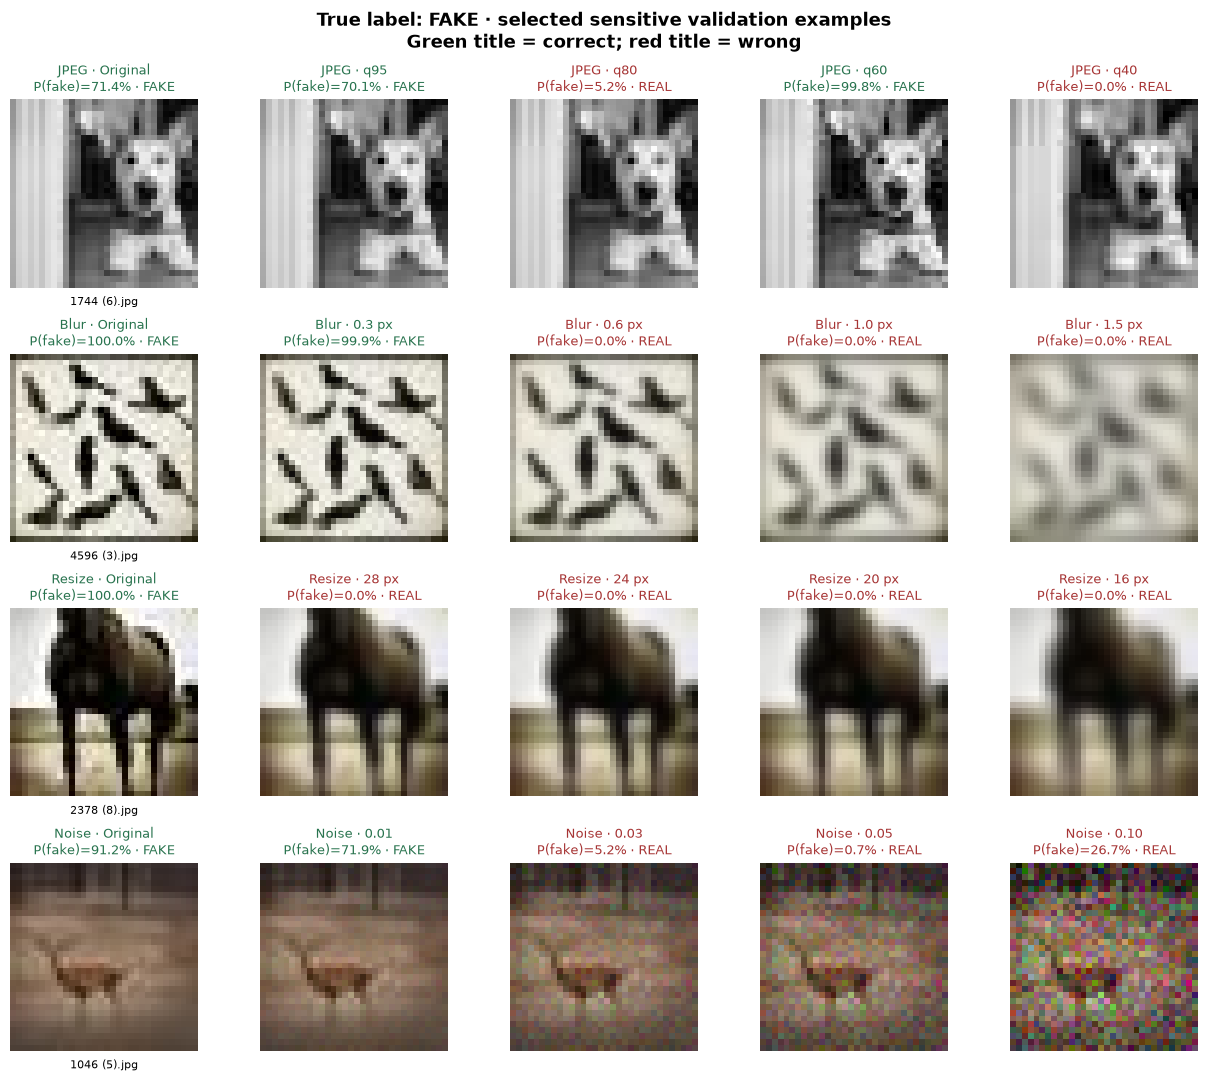

In [15]:
if behavior_arrays is not None:
    plot_behavior_gallery("FAKE")


### 5.2 What happens to real images?

The same changes can also cause a different kind of mistake: a real image may start to look fake to the model. We'll use the same layout for real validation images, again showing the original and all four strengths. Here the chosen examples have the largest rise in P(FAKE) at the second tested strength among images that were originally classified correctly. Comparing these rows with the fake-image gallery helps us see whether a modification shifts both classes in the same direction or affects them differently. An example may remain correctly classified even after a large score change, and a stronger modification may sometimes reverse an earlier change. The full-set plots below will show how common these behaviours are.

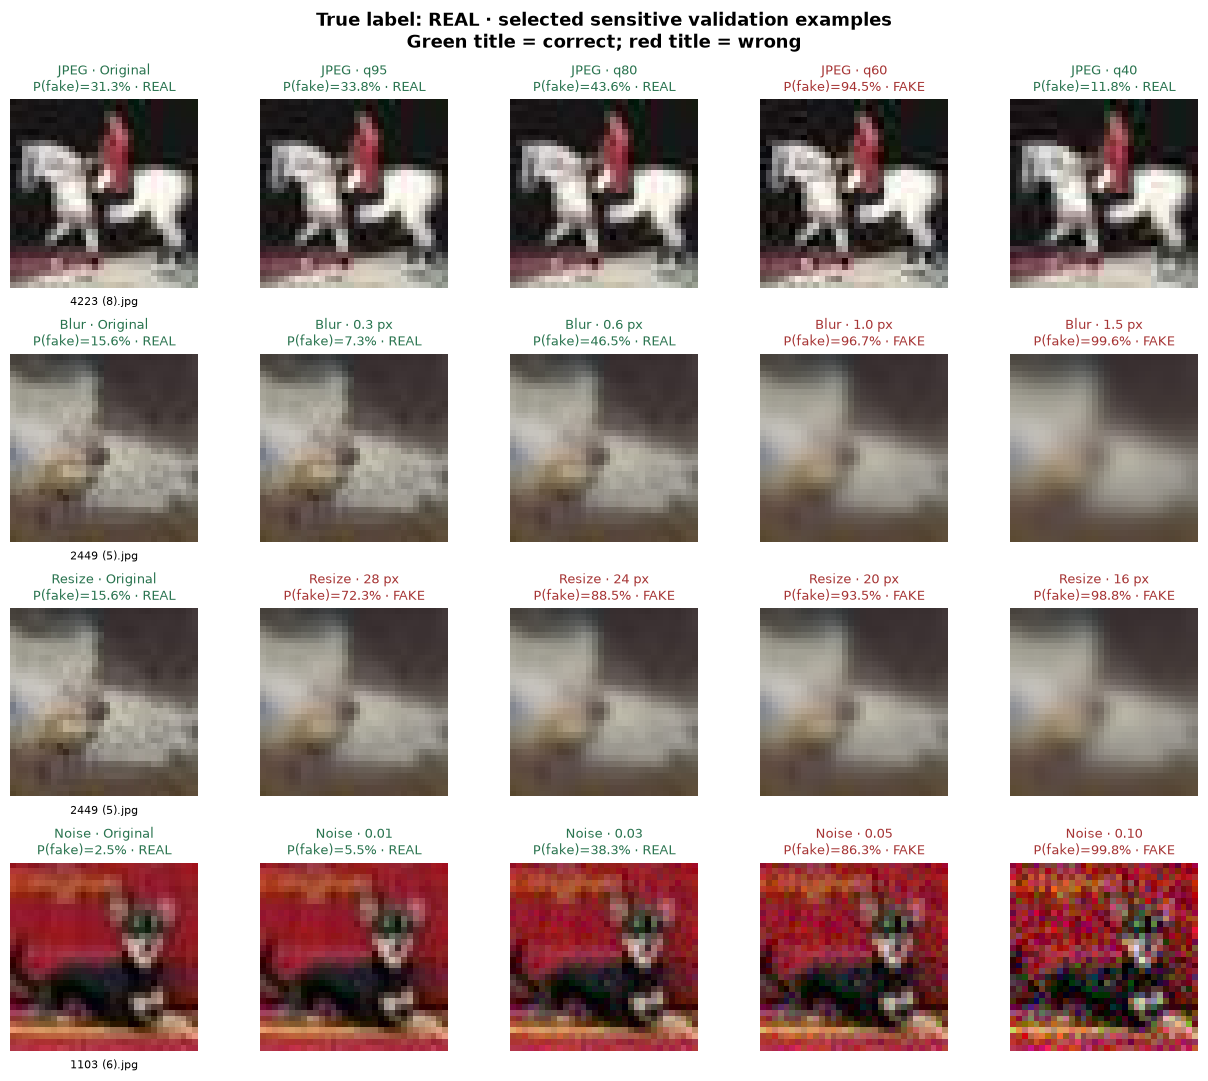

In [16]:
if behavior_arrays is not None:
    plot_behavior_gallery("REAL")


### 5.3 Compare behaviour across all validation images

The galleries make individual changes visible, but they were chosen to show sensitivity. We'll now use all 10,000 validation images to put those examples in context. Each panel will plot the original input and the four tested settings for one modification. The orange line shows the percentage of fake images correctly detected, the blue line shows the percentage of real images correctly accepted, and the dashed line shows overall accuracy. All three lines use the same percentage scale. If one class stays accurate while the other drops, the model may be shifting toward one predicted label, which an overall accuracy curve alone would hide. The horizontal settings are specific to each modification; the same position in different panels does not mean an equally strong visual change. Lines connect measured settings and do not represent results for untested strengths.

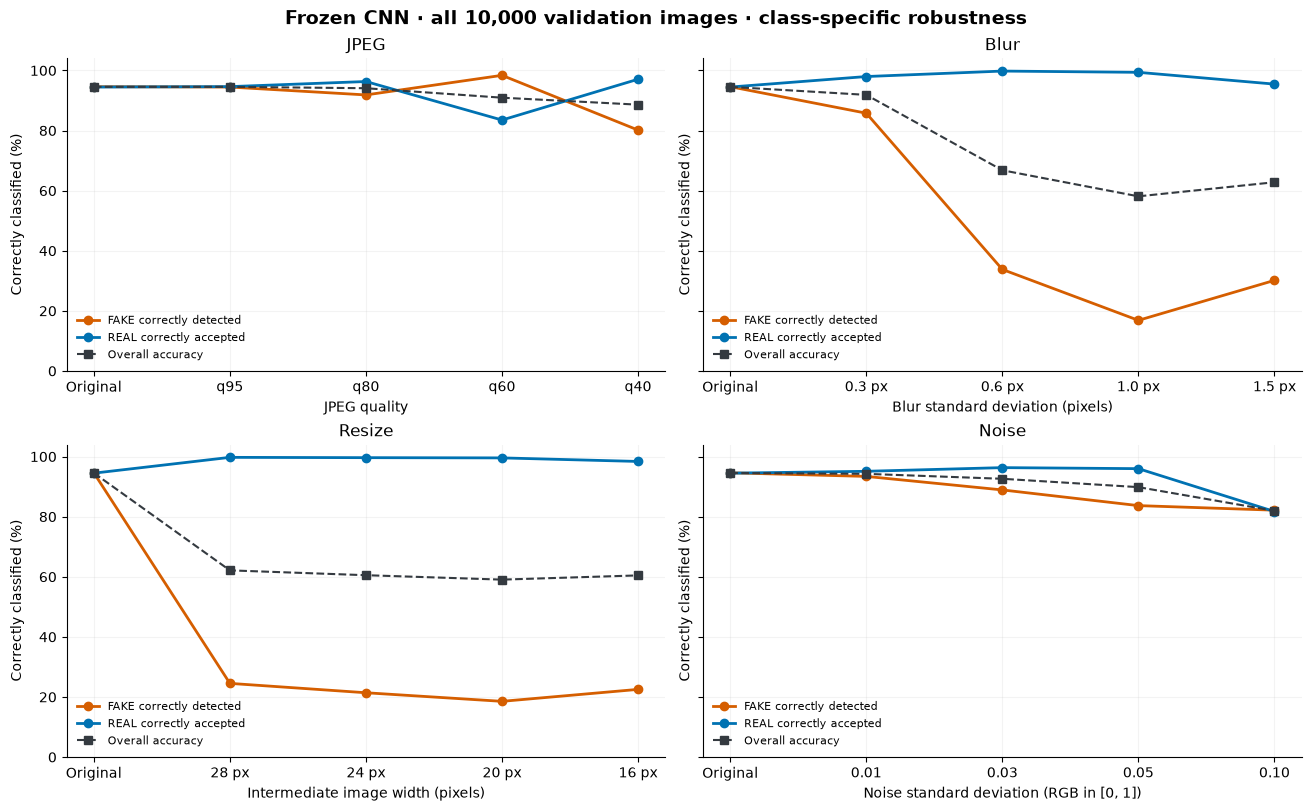

In [17]:
# Compare aggregate behaviour across all validation images, rather than only the selected gallery examples.
if behavior_arrays is not None:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained", sharey=True)
    for ax, (family, indices) in zip(axes.flat, behavior_groups.items()):
        x = np.arange(len(indices))
        ax.plot(
            x,
            100 * behavior_stats["fake_detected"][indices],
            color=behavior_colors["FAKE"],
            marker="o",
            label="FAKE correctly detected",
            lw=2,
        )
        ax.plot(
            x,
            100 * behavior_stats["real_accepted"][indices],
            color=behavior_colors["REAL"],
            marker="o",
            label="REAL correctly accepted",
            lw=2,
        )
        ax.plot(
            x,
            100 * behavior_stats["accuracy"][indices],
            color="#343a40",
            marker="s",
            ls="--",
            label="Overall accuracy",
            lw=1.5,
        )
        ax.set(
            title=family,
            xlabel=PROBE_FAMILIES[family]["axis"],
            ylabel="Correctly classified (%)",
            ylim=(0, 104),
            xticks=x,
            xticklabels=["Original"] + PROBE_FAMILIES[family]["labels"],
        )
        behavior_axes_style(ax)
        ax.legend(frameon=False, fontsize=8, loc="lower left")
    fig.suptitle(
        "Frozen CNN · all 10,000 validation images · class-specific robustness",
        fontsize=14,
        fontweight="bold",
    )
    finish_behavior_figure(fig, "robustness_curves")


### 5.4 See how the probability scores move

A label only tells us which side of the decision threshold an image falls on. To see the size and direction of the change, we'll plot each image's original P(FAKE) on the horizontal axis and its modified P(FAKE) on the vertical axis. Points on the diagonal have unchanged scores; points below it moved toward REAL and points above it moved toward FAKE. The horizontal and vertical lines at 0.5 divide the plot into regions where predictions stayed the same or switched labels. We'll show the same seeded sample of 400 real and 400 fake validation images in each panel, using the second tested setting for each modification. These settings are labelled explicitly and are not assumed to have equivalent severity. This view makes it possible to distinguish a general shift in scores from a few isolated label changes.

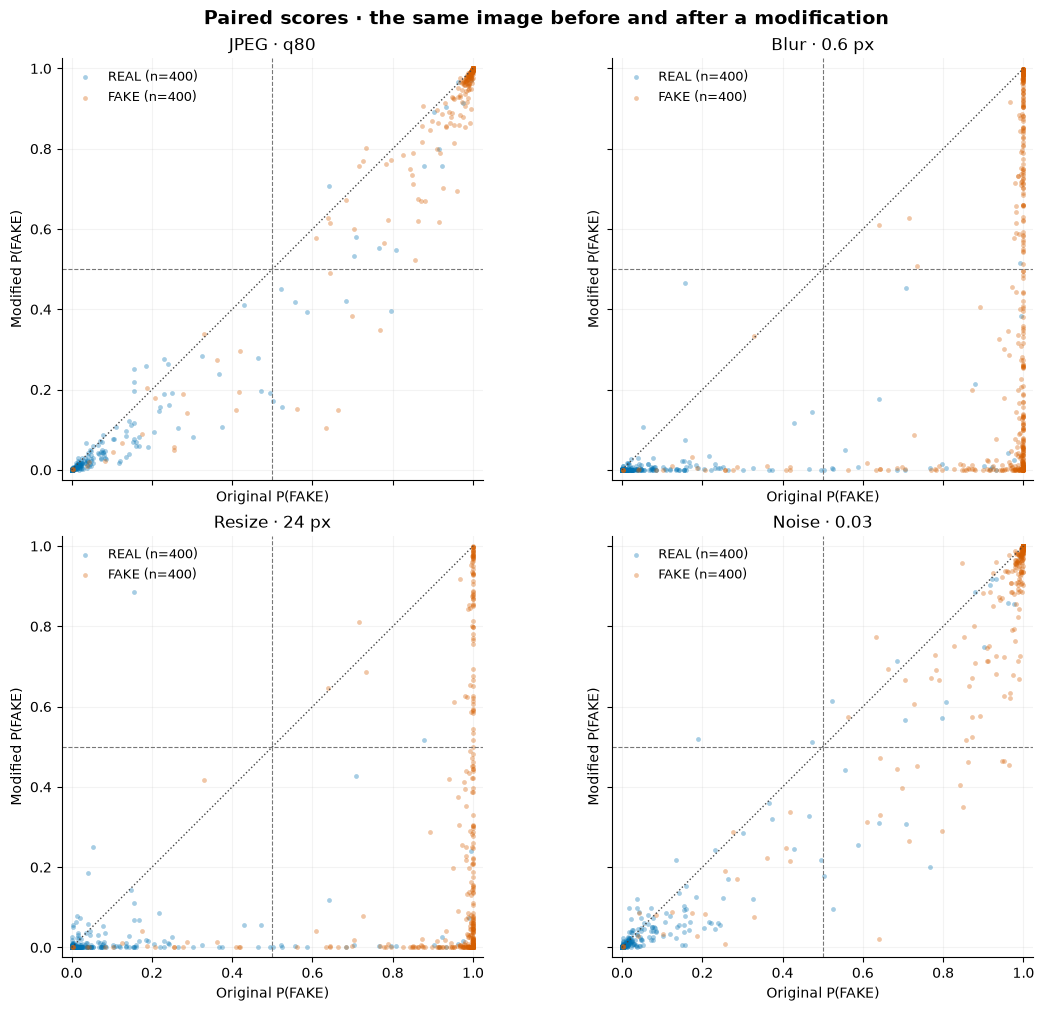

In [18]:
if behavior_arrays is not None:
    score_rng = np.random.default_rng(PROBE_SEED)
    behavior_scatter_ids = np.concatenate(
        [
            score_rng.choice(
                np.flatnonzero(behavior_labels == label), 400, replace=False
            )
            for label in [0, 1]
        ]
    )
    fig, axes = plt.subplots(
        2, 2, figsize=(11, 10), layout="constrained", sharex=True, sharey=True
    )
    for ax, (family, indices) in zip(axes.flat, behavior_groups.items()):
        condition_index = indices[2]
        for name, label in [("REAL", 1), ("FAKE", 0)]:
            ids = behavior_scatter_ids[behavior_labels[behavior_scatter_ids] == label]
            ax.scatter(
                behavior_scores[0, ids],
                behavior_scores[condition_index, ids],
                s=12,
                alpha=0.35,
                color=behavior_colors[name],
                linewidths=0,
                label=f"{name} (n=400)",
            )
        ax.plot([0, 1], [0, 1], ls=":", color="#444444", lw=1)
        ax.axvline(0.5, ls="--", color="#777777", lw=0.8)
        ax.axhline(0.5, ls="--", color="#777777", lw=0.8)
        ax.set(
            title=f"{family} · {behavior_conditions_list[condition_index]['label']}",
            xlabel="Original P(FAKE)",
            ylabel="Modified P(FAKE)",
            xlim=(-0.025, 1.025),
            ylim=(-0.025, 1.025),
            aspect="equal",
        )
        ax.legend(frameon=False, fontsize=9, loc="upper left")
        behavior_axes_style(ax)
    fig.suptitle(
        "Paired scores · the same image before and after a modification",
        fontsize=14,
        fontweight="bold",
    )
    finish_behavior_figure(fig, "paired_probability_scores")


### 5.5 Follow individual images across all modifications

We'll also display a small map of prediction changes to see whether the same images are sensitive to several modifications. Each row represents one validation image and each column represents one tested setting. Orange means an originally correct prediction became wrong, green means an originally wrong prediction became correct, and grey means the predicted label stayed the same. Grey therefore does not necessarily mean correct. We'll use a fixed random sample of 100 fake and 100 real images, and place images whose original scores were closer to 0.5 near the top of each class group. Reading across a row shows an image's pattern of changes; reading down a column shows which examples were affected by that setting. The image selection is illustrative, while the preceding robustness curves use the entire validation set.

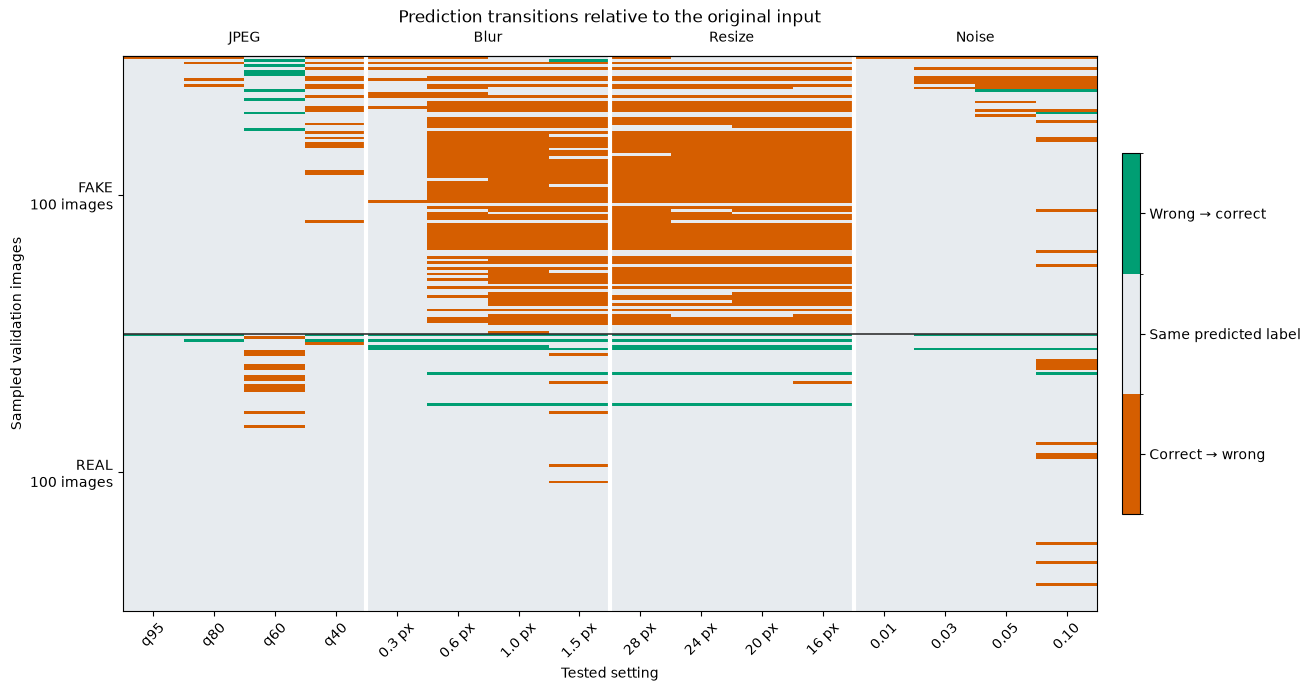

In [19]:
if behavior_arrays is not None:
    from matplotlib.colors import ListedColormap, BoundaryNorm

    transition_rng = np.random.default_rng(PROBE_SEED + 1)
    transition_ids = []
    for label in [0, 1]:
        ids = transition_rng.choice(
            np.flatnonzero(behavior_labels == label), 100, replace=False
        )
        ids = ids[np.argsort(np.abs(behavior_scores[0, ids] - 0.5), kind="stable")]
        transition_ids.extend(ids.tolist())
    transition_ids = np.asarray(transition_ids)
    all_correct = (behavior_scores > 0.5) == (behavior_labels == 0)[None, :]
    changes = all_correct[1:, transition_ids].astype(np.int8) - all_correct[
        0, transition_ids
    ].astype(np.int8)
    cmap = ListedColormap(["#D55E00", "#e7ebef", "#009E73"])
    fig, ax = plt.subplots(figsize=(13, 6.8), layout="constrained")
    heat = ax.imshow(
        changes.T,
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        norm=BoundaryNorm([-1.5, -0.5, 0.5, 1.5], 3),
    )
    for boundary in [3.5, 7.5, 11.5]:
        ax.axvline(boundary, color="white", lw=3)
    ax.axhline(99.5, color="#333333", lw=1.2)
    ax.set(
        xticks=np.arange(16),
        xticklabels=[c["label"] for c in behavior_conditions_list[1:]],
        yticks=[49.5, 149.5],
        yticklabels=["FAKE\n100 images", "REAL\n100 images"],
        xlabel="Tested setting",
        ylabel="Sampled validation images",
        title="Prediction transitions relative to the original input",
    )
    ax.tick_params(axis="x", labelrotation=45)
    top = ax.secondary_xaxis("top")
    top.set_xticks([1.5, 5.5, 9.5, 13.5], list(PROBE_FAMILIES))
    top.tick_params(length=0, pad=8)
    colorbar = fig.colorbar(heat, ax=ax, ticks=[-1, 0, 1], shrink=0.65, pad=0.025)
    colorbar.ax.set_yticklabels(
        ["Correct → wrong", "Same predicted label", "Wrong → correct"]
    )
    finish_behavior_figure(fig, "prediction_transitions")


### 5.6 Try the changes yourself

The explorer below lets us inspect these behaviours one image at a time. Choose an image, select a modification, and move the strength slider from the original to one of the four tested settings. The two thumbnails will show the original and modified pixels side by side, while the score plot will show that image's P(FAKE) across all settings of the selected modification. The highlighted point follows the slider, and the dashed line marks the decision threshold. The preview set includes the sensitive gallery cases, examples with large score movements toward the correct label among initially incorrect predictions, and a few randomly selected images. It is designed for inspection rather than estimating how often a behaviour occurs. The preview images and measured scores are bundled in this notebook, so these controls work with a live kernel even without the full dataset; moving them does not train or reevaluate the model.

In [20]:
if behavior_arrays is not None:
    import html
    import ipywidgets as widgets

    preview_choices = [
        (
            f"{'FAKE' if behavior_labels[int(index)]==0 else 'REAL'} · {behavior_arrays['paths'][int(index)]}",
            int(index),
        )
        for index in behavior_arrays["preview_indices"]
    ]
    behavior_image_choice = widgets.Dropdown(
        options=preview_choices,
        description="Image:",
        layout=widgets.Layout(width="95%"),
    )
    behavior_family_choice = widgets.Dropdown(
        options=list(PROBE_FAMILIES), description="Change:"
    )
    behavior_level_choice = widgets.IntSlider(
        value=2, min=0, max=4, step=1, description="Strength:", continuous_update=False
    )
    behavior_original_widget = widgets.Image(format="png", width=192, height=192)
    behavior_modified_widget = widgets.Image(format="png", width=192, height=192)
    behavior_original_label = widgets.HTML()
    behavior_modified_label = widgets.HTML()
    behavior_details_widget = widgets.HTML()
    behavior_trajectory_widget = widgets.Image(format="png")
    behavior_explorer_state = {}

    def behavior_png(image, size=192):
        stream = BytesIO()
        Image.fromarray(image.transpose(1, 2, 0)).resize(
            (size, size), Image.Resampling.NEAREST
        ).save(stream, format="PNG")
        return stream.getvalue()

    def update_behavior_explorer(change=None):
        index = int(behavior_image_choice.value)
        family = behavior_family_choice.value
        level = int(behavior_level_choice.value)
        indices = behavior_groups[family]
        condition_index = indices[level]
        condition = behavior_conditions_list[condition_index]
        original = behavior_previews[index]
        changed = modify_behavior_image(
            original, condition["family"], condition["value"], index
        )
        original_score = float(behavior_scores[0, index])
        changed_score = float(behavior_scores[condition_index, index])
        truth = "FAKE" if behavior_labels[index] == 0 else "REAL"
        predicted_original = "FAKE" if original_score > 0.5 else "REAL"
        predicted_changed = "FAKE" if changed_score > 0.5 else "REAL"
        behavior_original_widget.value = behavior_png(original)
        behavior_modified_widget.value = behavior_png(changed)
        behavior_original_label.value = (
            f"<b>Original</b><br>P(FAKE): {original_score:.1%} · {predicted_original}"
        )
        setting = "Original" if level == 0 else f"{family} · {condition['label']}"
        behavior_modified_label.value = (
            f"<b>{setting}</b><br>P(FAKE): {changed_score:.1%} · {predicted_changed}"
        )
        behavior_details_widget.value = (
            f"<b>True label: {truth}</b> · <code>{html.escape(str(behavior_arrays['paths'][index]))}</code><br>"
            f"Score change: {100*(changed_score-original_score):+.1f} percentage points · "
            f"Prediction {'changed' if predicted_original!=predicted_changed else 'stayed the same'}. "
            "Images are enlarged for viewing; the model input stays 32×32."
        )
        fig, ax = plt.subplots(figsize=(6.5, 3.0), layout="constrained")
        ax.plot(
            np.arange(5),
            behavior_scores[indices, index],
            marker="o",
            lw=2,
            color=behavior_colors[truth],
        )
        ax.scatter(
            [level],
            [changed_score],
            s=110,
            facecolors="none",
            edgecolors="#222222",
            linewidths=2,
            zorder=5,
        )
        ax.axhline(0.5, ls="--", color="#777777", lw=1)
        ax.set(
            xticks=np.arange(5),
            xticklabels=["Original"] + PROBE_FAMILIES[family]["labels"],
            ylim=(-0.04, 1.04),
            ylabel="P(FAKE)",
            xlabel=PROBE_FAMILIES[family]["axis"],
            title=f"{family} · score trajectory",
        )
        behavior_axes_style(ax)
        stream = BytesIO()
        fig.savefig(
            stream, format="png", dpi=120, bbox_inches="tight", facecolor="white"
        )
        plt.close(fig)
        behavior_trajectory_widget.value = stream.getvalue()
        behavior_explorer_state.update(
            index=index,
            condition_index=condition_index,
            score=changed_score,
            pixels=changed,
        )

    for control in [
        behavior_image_choice,
        behavior_family_choice,
        behavior_level_choice,
    ]:
        control.observe(update_behavior_explorer, names="value")
    update_behavior_explorer()
    display(
        widgets.VBox(
            [
                behavior_image_choice,
                widgets.HBox([behavior_family_choice, behavior_level_choice]),
                widgets.HBox(
                    [
                        widgets.VBox(
                            [behavior_original_label, behavior_original_widget]
                        ),
                        widgets.VBox(
                            [behavior_modified_label, behavior_modified_widget]
                        ),
                    ],
                    layout=widgets.Layout(gap="24px"),
                ),
                behavior_details_widget,
                behavior_trajectory_widget,
            ]
        )
    )
    print(
        "Run this cell with a live kernel to use the controls. The static figures above are available on GitHub."
    )


Run this cell with a live kernel to use the controls. The static figures above are available on GitHub.


### 5.7 What is worth investigating next?

The table below will bring a few measured settings back together so we can connect the image-level views with the full validation results. We'll compare overall accuracy, the fraction of fake images detected, false alarms on real images, and the fraction of all images whose predicted label changed from the original. The settings are examples from this exploratory sweep, not equally severe or optimized attacks. We can use these observations to choose image sequences, score trajectories, and before/after feature visualizations for the next part of the course. They describe how this fixed CNN responds under the specified processing choices; they do not establish why it learned that behaviour or how another model will respond.

In [21]:
if behavior_arrays is not None:
    example_indices = [
        0,
        behavior_groups["JPEG"][3],
        behavior_groups["Blur"][2],
        behavior_groups["Resize"][1],
        behavior_groups["Noise"][4],
    ]
    show_table(
        [
            "Input",
            "Accuracy",
            "FAKE detected",
            "REAL flagged FAKE",
            "Changed predicted label",
        ],
        [
            [
                (
                    "Original"
                    if i == 0
                    else f"{behavior_conditions_list[i]['family']} · {behavior_conditions_list[i]['label']}"
                ),
                f"{behavior_stats['accuracy'][i]:.2%}",
                f"{behavior_stats['fake_detected'][i]:.2%}",
                f"{behavior_stats['real_false_alarm'][i]:.2%}",
                f"{behavior_stats['changed_label'][i]:.2%}",
            ]
            for i in example_indices
        ],
    )
    resize_i, blur_i, jpeg_i = (
        behavior_groups["Resize"][1],
        behavior_groups["Blur"][2],
        behavior_groups["JPEG"][3],
    )
    display(
        Markdown(
            f"With **32 → 28 → 32 resizing**, accuracy changes from **{behavior_stats['accuracy'][0]:.2%}** to "
            f"**{behavior_stats['accuracy'][resize_i]:.2%}**, and **{behavior_stats['changed_label'][resize_i]:.2%}** of images switch predicted labels. "
            f"At **0.6-pixel blur**, fake detection is **{behavior_stats['fake_detected'][blur_i]:.2%}**, while "
            f"**{behavior_stats['real_accepted'][blur_i]:.2%}** of real images are still accepted as real. "
            f"At **JPEG quality 60**, fake detection is **{behavior_stats['fake_detected'][jpeg_i]:.2%}**, but "
            f"**{behavior_stats['real_false_alarm'][jpeg_i]:.2%}** of real images are flagged as fake. "
            "These class-specific movements give us concrete cases to follow in the galleries, paired-score plots, and explorer."
        )
    )


| Input | Accuracy | FAKE detected | REAL flagged FAKE | Changed predicted label |
| --- | --- | --- | --- | --- |
| Original | 94.54% | 94.60% | 5.52% | 0.00% |
| JPEG · q60 | 90.94% | 98.38% | 16.50% | 7.44% |
| Blur · 0.6 px | 66.79% | 33.78% | 0.20% | 33.09% |
| Resize · 28 px | 62.13% | 24.52% | 0.26% | 37.73% |
| Noise · 0.10 | 81.94% | 82.16% | 18.28% | 16.16% |

With **32 → 28 → 32 resizing**, accuracy changes from **94.54%** to **62.13%**, and **37.73%** of images switch predicted labels. At **0.6-pixel blur**, fake detection is **33.78%**, while **99.80%** of real images are still accepted as real. At **JPEG quality 60**, fake detection is **98.38%**, but **16.50%** of real images are flagged as fake. These class-specific movements give us concrete cases to follow in the galleries, paired-score plots, and explorer.

## 6. What the modification probe shows

The modification views answer part of that question. We kept each validation image and its label fixed, changed one property at a time, and followed the probability and predicted class. JPEG compression and moderate noise reduced accuracy, while even a small downsample-and-upsample operation caused a much larger change. Resizing from 32 to 28 pixels and back reduced the CNN's validation accuracy to **62.13%**; blur with radius 0.6 reduced it to **66.79%**. The score distributions and individual examples show why an average accuracy is not enough: we also need to see which class loses detections and whether many images move in the same direction. These are observations about the tested transformations, not proof that any particular image artifact is the cause.

The completed ResNet18 experiment gives us a second reference:

| Condition | Plain CNN accuracy | Fine-tuned ResNet18 accuracy |
| --- | ---: | ---: |
| Clean official test, 20,000 images | 94.290% | 97.735% |
| Original validation images | 94.54% | 97.92% |
| JPEG quality 60 | 90.94% | 96.24% |
| Gaussian blur, radius 0.6 | 66.79% | 63.69% |
| Resize 32 → 28 → 32 | 62.13% | 55.77% |
| Gaussian noise, standard deviation 0.05 | 89.83% | 90.68% |

Except for the explicitly marked official test row, these measurements use the same **10,000 validation images**, their original labels and the fixed 0.5 decision threshold.

ResNet18 is more accurate on clean images and at the listed JPEG and noise settings, but it performs worse than the small CNN at the listed blur and resize settings. A larger model with ImageNet pretraining therefore did not remove this sensitivity. This comparison changes several things together—architecture, initialization, input resizing and normalization—so it cannot isolate the effect of architecture alone. The table also shows selected settings from the full sweep; the complete curves are needed to see how behaviour changes with strength.

**Where Phase I continues.** `03_resnet18_behaviour.ipynb` shows the full ResNet18 curves next to these. `04_what_fools_the_detectors.ipynb` adds sharpening and colour edits (29 conditions) and shows that blur, resizing, JPEG and sharpening all move the output along one sharpness dial: sharpening real photos by 200 % raises the CNN's false alarms from 5.5 % to 83.7 %, and sharpening blurred fakes again brings detection back from 33.8 % to 88.6 %. It also breaks the errors down by object class, colour, image group and model agreement.